In [12]:
import pandas as pd
import numpy as np

In [13]:
data = pd.read_csv("~/Downloads/kickstarter_projects.csv")
data_np = data.to_numpy()
data.head()

,ID,Name,Category,Subcategory,Country,Launched,Deadline,Goal,Pledged,Backers,State
0,1860890148,Grace Jones Does Not Give A F$#% T-Shirt (limi...,Fashion,Fashion,United States,2009-04-21 21:02:48,2009-05-31,1000,625,30,Failed
1,709707365,CRYSTAL ANTLERS UNTITLED MOVIE,Film & Video,Shorts,United States,2009-04-23 00:07:53,2009-07-20,80000,22,3,Failed
2,1703704063,drawing for dollars,Art,Illustration,United States,2009-04-24 21:52:03,2009-05-03,20,35,3,Successful
3,727286,Offline Wikipedia iPhone app,Technology,Software,United States,2009-04-25 17:36:21,2009-07-14,99,145,25,Successful
4,1622952265,Pantshirts,Fashion,Fashion,United States,2009-04-27 14:10:39,2009-05-26,1900,387,10,Failed


In [17]:
print(data.columns)
print(data['State'].unique())
live_data = data[data['State'] == "Live"]
live_data["Launched"] =pd.to_datetime(live_data["Launched"])
live_data["Deadline"] = pd.to_datetime(live_data["Deadline"])
live_data["Duration"] = (live_data["Deadline"] - live_data["Launched"]).dt.days

data.describe()

Index(['ID', 'Name', 'Category', 'Subcategory', 'Country', 'Launched',
       'Deadline', 'Goal', 'Pledged', 'Backers', 'State'],
      dtype='object')
['Failed' 'Successful' 'Canceled' 'Suspended' 'Live']


/var/folders/dz/wrg2699d4jq7zd26swc8s2wm0000gn/T/ipykernel_66595/263733930.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  live_data["Launched"] =pd.to_datetime(live_data["Launched"])
/var/folders/dz/wrg2699d4jq7zd26swc8s2wm0000gn/T/ipykernel_66595/263733930.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  live_data["Deadline"] = pd.to_datetime(live_data["Deadline"])
/var/folders/dz/wrg2699d4jq7zd26swc8s2wm0000gn/T/ipykernel_66595/263733930.py:6: SettingWithCopyWarning: 
A value is trying to be set o

,ID,Goal,Pledged,Backers
count,3.748530e+05,3.748530e+05,3.748530e+05,374853.000000
mean,1.074656e+09,4.586378e+04,9.121073e+03,106.690359
std,6.191377e+08,1.158778e+06,9.132054e+04,911.718520
min,5.971000e+03,0.000000e+00,0.000000e+00,0.000000
25%,5.380728e+08,2.000000e+03,3.100000e+01,2.000000
50%,1.075300e+09,5.500000e+03,6.250000e+02,12.000000
75%,1.610149e+09,1.600000e+04,4.051000e+03,57.000000
max,2.147476e+09,1.663614e+08,2.033899e+07,219382.000000


In [19]:
rows_with_nan = data[data.isna().any(axis=1)]
print(data.shape[0])


374853


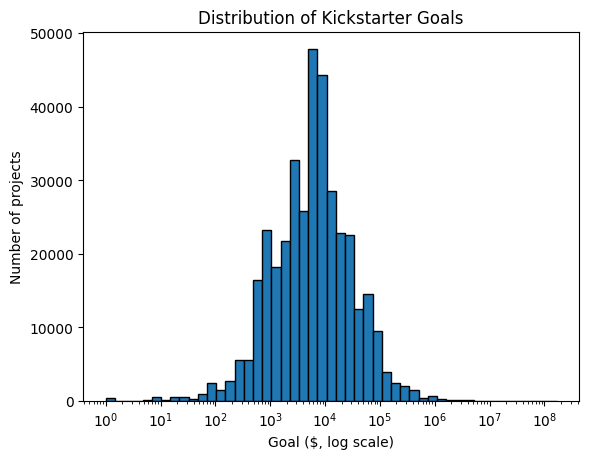

In [23]:
from matplotlib import pyplot as plt


goal = data["Goal"].to_numpy(dtype=float)
goal = goal[goal > 0]                       # a log axis can't show 0

bins = np.logspace(np.log10(goal.min()), np.log10(goal.max()), 50)

plt.hist(goal, bins=bins, edgecolor="black")
plt.xscale("log")
plt.xlabel("Goal ($, log scale)")
plt.ylabel("Number of projects")
plt.title("Distribution of Kickstarter Goals")
plt.show()